[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MusicalInformatics/miws26/blob/main/symbolic_tasks_II/melody_id/melody_identification.ipynb)

# Melody Identification with CNNs

In many musical traditions, the **melody** is the most significant line of a piece, while the **accompaniment** provides harmonic and rhythmic support. Listeners can usually tell them apart, but doing it only from the written score is much harder. In this notebook we study the approach of

> Simonetta, F., Cancino-Chacón, C., Ntalampiras, S., & Widmer, G. (2019). *A Convolutional Approach to Melody Line Identification in Symbolic Scores*. In Proceedings of the 20th International Society for Music Information Retrieval Conference (ISMIR), Delft, The Netherlands.

which uses a convolutional neural network (CNN) on a **piano roll** representation of the score. The original code was written in Python 2 with Theano; here we use a PyTorch re-implementation that can load the weights trained by the authors.

In [ ]:
import os
import sys

try:
    import google.colab

    IN_COLAB = True
except:
    IN_COLAB = False

if IN_COLAB:
    # Install python packages
    ! pip install git+https://github.com/CPJKU/partitura.git@develop

    # To be able to access helper modules and data in the repo for this tutorial
    # (not necessary if the jupyter notebook is run locally instead of google colab)
    if not os.path.exists("./miws26"):
        !git clone https://github.com/MusicalInformatics/miws26.git
    sys.path.insert(0, "./miws26/symbolic_tasks_II/melody_id/")
    NOTEBOOK_DIR = os.path.abspath("./miws26/symbolic_tasks_II/melody_id")
else:
    # The notebook is in the melody_id folder
    NOTEBOOK_DIR = os.path.abspath(".")
    sys.path.insert(0, NOTEBOOK_DIR)

# The datasets are downloaded to this folder
DATASETS_DIR = os.path.join(NOTEBOOK_DIR, "datasets")

In [ ]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import HTML, Audio, display

from melody_cnn import MelodyCNN, get_device, load_pretrained
from melody_training import augment_melody, pianoroll_windows, train_model
from melody_utils import (
    BEAT_DIV,
    MELODY_CMAP,
    MELODY_COLOR,
    SCORE_CMAP,
    cluster_threshold,
    excerpt_notes,
    get_challenge_files,
    labels_to_pianoroll,
    load_notes,
    make_pianorolls,
    monophonic_melody,
    note_level_scores,
    note_probabilities,
    plot_pianoroll,
    predict_pianoroll,
    split_windows,
    synthesize_notes,
    to_partitura_note_array,
)
from graph_animation import animate_graph_search
from skyline import animate_skyline, skyline
from train_melody_id import split_by_work, work_of

warnings.filterwarnings("ignore", module="partitura")

## 1. Introduction

In **melody identification**, we want to assign to each note $n_i$ a label $y_i \in \{0, 1\}$, where $y_i = 1$ means that the note belongs to the melody. This is a binary classification problem, but the notes of a score are not independent examples: whether a note is part of the melody depends on its context (the surrounding notes, their registers and rhythms).

The idea of the paper by Simonetta et al. (2019) to avoid hand-crafted features of the notes and to work directly on a **piano roll**, a 2D image of the score where the horizontal axis is the score time and the vertical axis is the pitch. Basically, we reduce the problem to a filtering approach.

A piece of $T$ pixels is represented by a binary matrix $X \in \{0,1\}^{128 \times T}$. The melody is another piano roll $Y \in \{0,1\}^{128 \times T}$ that has only the pixels of the melody notes (so $Y \le X$). A CNN is trained to predict $Y$ from $X$: its output $P \in [0, 1]^{128 \times T}$ gives, for each pixel, the probability of belonging to the melody.

### 1.1 Dataset

We use the **Mozart dataset** of the paper, in which a professional pianist annotated the main melody line of Mozart's piano sonatas. For the challenge, it is distributed as the zip file of the dataset on Moodle (see the README): unzip it in the folder `datasets/melody_id_challenge` of this folder. The **training set** has 29 movements of 10 sonatas (with the annotations). The test set (9 movements of 3 other sonatas) has no annotations: it is evaluated on the challenge server.

Each piece is a csv file with one row for each note: its onset and duration (in beats, i.e., quarter notes), its pitch, and `melody`, which is 1 if the note is part of the melody.

In [ ]:
# The training set of the challenge (zip file from Moodle, unzipped in datasets/melody_id_challenge)
mozart_files = get_challenge_files(DATASETS_DIR, "train")

# We split the pieces by sonata (the movements of a sonata always go together): 23 pieces to train and 6 to validate
train_files, val_files, _ = split_by_work(mozart_files)

print(f"{len(mozart_files)} pieces of the training set of the challenge:")
print(", ".join(os.path.basename(f).replace(".csv", "") for f in mozart_files))

Let's load the first movement of the Piano Sonata K. 279 in C major. The note array has the fields `pitch`, `onset` and `duration` (in beats), and `soprano`, which is 1 if the note is part of the melody (the `melody` column of the csv file).

In [ ]:
piece_file = [f for f in train_files if f.endswith("kv279_1.csv")][0]
note_array = load_notes(piece_file)

print(f"{len(note_array)} notes, of which {note_array['soprano'].sum()} belong to the melody")
note_array[:10]

We compute the piano roll of the whole score and the piano roll of the melody with [`partitura.utils.compute_pianoroll`](https://partitura.readthedocs.io/en/latest/modules/partitura.utils.html#partitura.utils.compute_pianoroll). The function `make_pianorolls` in `melody_utils.py` calls it twice (once with all the notes, once with the melody notes only), using 8 pixels per beat and shortening each note by one pixel, so that consecutive notes of the same pitch can be told apart.

In [ ]:
score_pr, melody_pr, note_idx = make_pianorolls(note_array, beat_div=BEAT_DIV)

print("Piano roll of the score:", score_pr.shape, "(pitches x pixels)")
print(f"Duration: {score_pr.shape[1] / BEAT_DIV:.0f} beats; {score_pr.mean():.2%} of the pixels are active")

We can now see what the model works with. The **input** is the piano roll of the full score, and the **output** that we want the model to produce is the piano roll of the melody: it has the same size as the input, but only the pixels of the melody notes are active. Here are the first 16 beats (4 bars in 4/4) of the piece.

In [ ]:
def plot_input_and_output(start_beat=0, n_beats=16):
    cols = slice(start_beat * BEAT_DIV, (start_beat + n_beats) * BEAT_DIV)
    active_pitches = np.nonzero(score_pr[:, cols].any(axis=1))[0]
    pitch_range = (active_pitches.min() - 2, active_pitches.max() + 2)

    fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
    panels = [
        (score_pr, SCORE_CMAP, "Input: piano roll of the full score"),
        (melody_pr, MELODY_CMAP, "Output: piano roll of the melody"),
    ]
    for ax, (pianoroll, cmap, title) in zip(axes, panels):
        plot_pianoroll(pianoroll[:, cols], ax=ax, cmap=cmap, title=title, pitch_range=pitch_range)
    # the time axis of the excerpt starts at start_beat
    for ax in axes:
        ax.set_xticks(np.arange(0, n_beats + 1, 4))
        ax.set_xticklabels(np.arange(start_beat, start_beat + n_beats + 1, 4))
    axes[-1].set_xlabel("Score time (beats)")
    fig.tight_layout()
    return fig


fig = plot_input_and_output(start_beat=0, n_beats=16)
plt.show()

It is also useful to **listen** to the task. We can synthesize the excerpt with partitura: if [fluidsynth](https://www.fluidsynth.org/) is installed (through `pyfluidsynth`), partitura renders the notes with a sampled piano sound (`partitura.utils.fluidsynth.synthesize_fluidsynth`); otherwise it uses additive synthesis (`partitura.utils.synth.synthesize`), which sounds more artificial but always works. The function `synthesize_notes` in `melody_utils.py` chooses the one that is available.

First the full excerpt (the input), and then only the melody (the output the model should produce).

In [ ]:
BPM = 120
SAMPLERATE = 22050

full_notes = excerpt_notes(note_array, start_beat=0, n_beats=16)
melody_notes = excerpt_notes(note_array, start_beat=0, n_beats=16, melody_only=True)
print(f"Full excerpt: {len(full_notes)} notes. Melody: {len(melody_notes)} notes.")

print("Full excerpt (input)")
display(Audio(synthesize_notes(full_notes, bpm=BPM, samplerate=SAMPLERATE), rate=SAMPLERATE))
print("Melody (output)")
display(Audio(synthesize_notes(melody_notes, bpm=BPM, samplerate=SAMPLERATE), rate=SAMPLERATE))

## 2. Baseline: the skyline algorithm

The simplest approach to melody identification is the **skyline algorithm** (Uitdenbogerd & Zobel, 1999). It assumes that the melody is always the highest voice, which is often true in Western art music, pop and many folk traditions. The algorithm goes through the notes of the score from left to right and, for each onset, selects the note with the highest pitch as the melody note. All the other notes that start at the same moment are labeled as accompaniment.

The animation shows how it works on the first 8 beats of the piece. For each onset, it first looks at the notes that start at that moment (blue outline), and then it selects the highest one (red). Use the controls below the animation to go through the steps.

In [ ]:
excerpt = excerpt_notes(note_array, start_beat=0, n_beats=8)
anim = animate_skyline(excerpt, interval=800)
HTML(anim.to_jshtml())

Note what happens at the beginning of the piece. First, while the first melody note is held, the left hand plays three short notes. Since the skyline algorithm only looks at the onsets, these notes are the highest ones that start at their onset, and it labels them as melody. Then, at beat 1, the melody has a rest, so the only note that starts there is a bass note, which is also labeled as melody. The algorithm always has to choose one note per onset: it cannot take into account the notes that are still sounding, it cannot identify rests in the melody, and it fails when the melody is not the highest voice.

Let's apply the algorithm to the 16-beat excerpt, and compare its prediction with the target.

In [ ]:
notes = to_partitura_note_array(note_array)  # all the notes of the piece (without grace notes)
is_melody_true = notes["soprano"] == 1
is_melody_skyline = skyline(notes)

skyline_pr = labels_to_pianoroll(note_idx, is_melody_skyline, score_pr.shape[1])

start_beat, n_beats = 0, 16
cols = slice(start_beat * BEAT_DIV, (start_beat + n_beats) * BEAT_DIV)
active_pitches = np.nonzero(score_pr[:, cols].any(axis=1))[0]
pitch_range = (active_pitches.min() - 2, active_pitches.max() + 2)

fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
panels = [
    (score_pr, SCORE_CMAP, "Input: piano roll of the full score"),
    (melody_pr, MELODY_CMAP, "Target: piano roll of the melody"),
    (skyline_pr, MELODY_CMAP, "Prediction of the skyline algorithm"),
]
for ax, (pianoroll, cmap, title) in zip(axes, panels):
    plot_pianoroll(pianoroll[:, cols], ax=ax, cmap=cmap, title=title, pitch_range=pitch_range)
    ax.set_xticks(np.arange(0, n_beats + 1, 4))
    ax.set_xticklabels(np.arange(start_beat, start_beat + n_beats + 1, 4))
axes[-1].set_xlabel("Score time (beats)")
fig.tight_layout()
plt.show()

### 2.1 Evaluation

We evaluate the predictions at the **note level**: each note of the score is either predicted as melody or not, and we compare it with the annotation. The melody notes are the positive class and the accompaniment notes are the negative class, so for a piece:

* **TP** (true positives) are melody notes that the system labels as melody,
* **FP** (false positives) are accompaniment notes that the system labels as melody, and
* **FN** (false negatives) are melody notes that the system misses (labels as accompaniment).

$$
\text{Precision} = \frac{TP}{TP + FP}, \qquad \text{Recall} = \frac{TP}{TP + FN}, \qquad F_1 = \frac{2 \cdot \text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}
$$

What do they tell us about the notes?

* **Precision**: of all the notes that the system labels as melody, which fraction really are melody. A low precision means that the system "contaminates" the melody with accompaniment notes.
* **Recall**: of all the melody notes of the annotation, which fraction the system finds. A low recall means that there are holes in the melody: melody notes that the system does not recognize.
* **F1-score**: the harmonic mean of both. It is only high if the precision *and* the recall are high.

Neither of the two alone is enough. A dummy system that **labels every note as melody** finds all the melody notes, so its recall is perfect (1.0), but its precision is just the fraction of the notes of the piece that are melody (roughly half of them in these pieces), so its F1-score is far from perfect. Conversely, a system that labels as melody only one note, of which it is very sure, has a very high precision but a recall close to 0.

Here is the result of the skyline algorithm and of the dummy system for this piece, and the average over the **training pieces** (we do not use the validation pieces yet).

In [ ]:
precision, recall, f1 = note_level_scores(is_melody_true, is_melody_skyline)
print(f"{os.path.basename(piece_file)}: skyline precision = {precision:.3f}, recall = {recall:.3f}, F1 = {f1:.3f}")

# Dummy system: every note is labeled as melody
is_melody_all = np.ones(len(is_melody_true), dtype=bool)
precision, recall, f1 = note_level_scores(is_melody_true, is_melody_all)
print(f"{os.path.basename(piece_file)}: dummy    precision = {precision:.3f}, recall = {recall:.3f}, F1 = {f1:.3f}")

scores, scores_dummy = [], []
for f in train_files:
    piece_notes = to_partitura_note_array(load_notes(f))
    true = piece_notes["soprano"] == 1
    scores.append(note_level_scores(true, skyline(piece_notes)))
    scores_dummy.append(note_level_scores(true, np.ones(len(true), dtype=bool)))
scores, scores_dummy = np.array(scores), np.array(scores_dummy)

names = [os.path.basename(f).replace(".csv", "") for f in train_files]
for name, sc in [("Skyline", scores), ("Dummy (all notes)", scores_dummy)]:
    print(f"{name:18s} mean over {len(names)} training pieces: precision = {sc[:, 0].mean():.3f}, "
          f"recall = {sc[:, 1].mean():.3f}, F1 = {sc[:, 2].mean():.3f}")

fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(names, scores[:, 2], color="gray")
ax.axhline(scores[:, 2].mean(), color="k", linestyle="--", label="mean (skyline)")
ax.axhline(scores_dummy[:, 2].mean(), color=MELODY_COLOR, linestyle=":", label="mean (dummy: all notes)")
ax.set_ylabel("F1-score")
ax.set_ylim(0, 1)
ax.legend()
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

The recall of the skyline algorithm is almost perfect, because the melody of these pieces is almost always the highest voice. However, its precision is lower: it labels as melody a note at *every* onset, including those where the right hand does not play (rests in the melody) and the notes in the left hand. Can a model do better by learning from the data? That is what the CNN will do.

## 3. The CNN

The core of the method is a **fully convolutional neural network** that takes a piano roll window and returns a window of the same size, in which each pixel is the probability of belonging to the melody. The authors found the architecture with hyper-parameter optimization (Figure 3 of the paper):

1. `conv1`: 21 kernels of size $32 \times 16$ (pitch $\times$ time), i.e., a bit more than two and a half octaves and 2 beats.
2. `conv2`: another 21 kernels of the same size, followed by a sigmoid.
3. A "decoder" that goes back to the size of the input, using **transposed convolutions that share the weights** with `conv2` and `conv1` (as in an auto-encoder with tied weights), followed by a sigmoid.
4. **Masking**: the output is multiplied by the input piano roll, so that only the pixels where there is a note can have a non-zero probability.

There are no biases and no other parameters. We use a PyTorch implementation (`melody_cnn.py`) with the weights that the authors trained on the Mozart dataset.

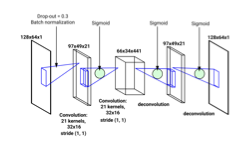

*Architecture of the CNN. Figure 3 in Simonetta et al. (2019).*

In [ ]:
device = get_device()
model = load_pretrained("mozart", device=device)
print(model)
print(f"Number of parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"Device: {device}")

### 3.1 Applying the CNN to a window

The CNN works on windows of 128 pitches $\times$ 64 pixels (8 beats). Let's take the first window of the piece (the first 8 beats) and pass it through the network. The input has the shape `(batch, channels, pitches, pixels)`.

We run it twice: with the masking turned off to see the output of the convolutional layers, and with the masking turned on to see the final output.

In [ ]:
WIN_WIDTH = 64
window = score_pr[:, :WIN_WIDTH]
window_target = melody_pr[:, :WIN_WIDTH]
x = torch.from_numpy(window)[None, None].to(device)  # (1, 1, 128, 64)

with torch.no_grad():
    model.eval()
    model.masking = False
    network_output = model(x)[0, 0].cpu().numpy()
    model.masking = True
    masked_output = model(x)[0, 0].cpu().numpy()

print("Input:", tuple(x.shape), "->  output:", masked_output.shape)

In [ ]:
active_pitches = np.nonzero(window.any(axis=1))[0]
pitch_range = (active_pitches.min() - 2, active_pitches.max() + 2)

fig, axes = plt.subplots(4, 1, figsize=(10, 9), sharex=True)
panels = [
    (window, SCORE_CMAP, "Input: piano roll of the score"),
    (window_target, MELODY_CMAP, "Target: piano roll of the melody"),
    (network_output, MELODY_CMAP, "Output of the network (without masking)"),
    (masked_output, MELODY_CMAP, "Output of the network, masked with the input"),
]
for ax, (pianoroll, cmap, title) in zip(axes, panels):
    plot_pianoroll(pianoroll, ax=ax, cmap=cmap, title=title, pitch_range=pitch_range)
axes[-1].set_xlabel("Score time (beats)")
fig.tight_layout()
plt.show()

Without the masking, the network output is close to 1 almost everywhere: the network only lowers the probability in the regions where the accompaniment is (for example, around the low notes and the chord at beat 4). Since we only care about the pixels where there is a note, the masking keeps only those pixels. In the final output, most of the notes of the melody are dark red (high probability), while most of the accompaniment is light or white. The network has clearly learned something about the task, but it is not perfect: some accompaniment notes, such as the notes of the chord at beat 4 or the notes of the first chord, still have a high probability. Also note that near the left and right borders of the window the network has less context, so its output is less reliable.

## 4. From the CNN output to a melody line

**But this is not yet a melody.** The CNN only gives us a probability for each *pixel* of a window of 8 beats. To obtain the melody line (a list of notes) we still need to:

1. process the whole piece with overlapping windows and combine the outputs of the windows,
2. turn the probabilities of the pixels into a probability for each *note*,
3. decide which notes are melody (a threshold), and
4. make sure that the result is a melody *line* (one note at a time).

We will build these steps one by one.

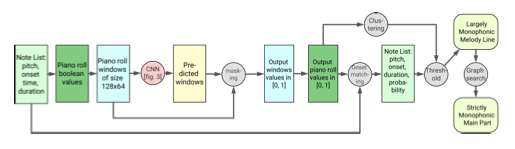

*The complete pipeline of the method, from the note list to the strictly monophonic melody. Figure 2 in Simonetta et al. (2019).*

### 4.1 The whole piece with overlapping windows

The piano roll of the piece is split into windows of 64 pixels with 50% overlap (the first one starts 4 beats before the piece, so that every pixel is in two windows). The CNN is applied to every window, and the output of the piece is the average of the (masked) outputs of the windows.

In [ ]:
windows = split_windows(score_pr)
print(f"{score_pr.shape[1]} pixels -> {len(windows)} windows of shape {windows.shape[1:]}")

output_pr = predict_pianoroll(model, score_pr)  # CNN on every window + average of the overlapping windows


def plot_panels(panels, start_beat=0, n_beats=16):
    cols = slice(start_beat * BEAT_DIV, (start_beat + n_beats) * BEAT_DIV)
    active = np.nonzero(score_pr[:, cols].any(axis=1))[0]
    fig, axes = plt.subplots(len(panels), 1, figsize=(10, 2.3 * len(panels)), sharex=True)
    for ax, (pianoroll, cmap, title) in zip(axes, panels):
        plot_pianoroll(pianoroll[:, cols], ax=ax, cmap=cmap, title=title, pitch_range=(active.min() - 2, active.max() + 2))
        ax.set_xticks(np.arange(0, n_beats + 1, 4))
        ax.set_xticklabels(np.arange(start_beat, start_beat + n_beats + 1, 4))
    axes[-1].set_xlabel("Score time (beats)")
    fig.tight_layout()
    plt.show()


plot_panels([(score_pr, SCORE_CMAP, "Input"), (melody_pr, MELODY_CMAP, "Target"), (output_pr, MELODY_CMAP, "Output of the CNN")])

### 4.2 From pixels to notes

The CNN gives a probability for each pixel, but we want one for each note. The probability of a note is the **median** of the probabilities of its pixels.

In [ ]:
note_probs = note_probabilities(output_pr, note_idx)  # one value per note
note_prob_pr = labels_to_pianoroll(note_idx, note_probs, score_pr.shape[1])

plot_panels([(melody_pr, MELODY_CMAP, "Target"), (note_prob_pr, MELODY_CMAP, "Probability of each note")])

### 4.3 Which notes are melody? The threshold

A note is melody if its probability is above a threshold. A fixed threshold (e.g., 0.5) is not ideal, since the distribution of the probabilities changes from piece to piece. The paper selects a threshold for each piece by clustering the note probabilities in two groups with single-linkage hierarchical clustering. The threshold is the largest value of the lower cluster.

In [ ]:
threshold = cluster_threshold(note_probs)

fig, ax = plt.subplots(figsize=(10, 2.5))
ax.hist(note_probs, bins=50, color="gray")
ax.axvline(0.5, color="k", linestyle=":", label="fixed threshold (0.5)")
ax.axvline(threshold, color=MELODY_COLOR, label=f"clustering threshold ({threshold:.2f})")
ax.set_xlabel("Probability of the note")
ax.set_ylabel("Number of notes")
ax.legend()
plt.show()

for name, th in [("fixed threshold", 0.5), ("clustering threshold", threshold)]:
    p, r, f = note_level_scores(is_melody_true, note_probs >= th)
    print(f"{name:21s}: precision = {p:.3f}, recall = {r:.3f}, F1 = {f:.3f}")

### 4.4 A melody line, not a chord: graph search

Several notes that sound at the same time can pass the threshold, but the melody is a **line**. To get a strictly monophonic melody, the paper builds a graph (Algorithm 1) with a node for each note above the threshold, plus a start and an end node. Each note is connected to the notes that start next (after it ends), with weight equal to the negative of the probability of the next note. The melody is the **shortest path** from the start to the end node: the sequence of non-overlapping notes with the highest total probability (`monophonic_melody` in `melody_utils.py`).

In [ ]:
is_melody_cnn = monophonic_melody(note_probs, note_idx, threshold)
above = note_probs >= threshold

plot_panels([
    (melody_pr, MELODY_CMAP, "Target"),
    (labels_to_pianoroll(note_idx, above, score_pr.shape[1]), MELODY_CMAP, "Notes above the threshold"),
    (labels_to_pianoroll(note_idx, is_melody_cnn, score_pr.shape[1]), MELODY_CMAP, "Melody line (shortest path)"),
])

for name, pred in [("above the threshold", above), ("shortest path", is_melody_cnn)]:
    p, r, f = note_level_scores(is_melody_true, pred)
    print(f"{name:20s}: precision = {p:.3f}, recall = {r:.3f}, F1 = {f:.3f}")

The animation shows the search on the first 8 beats. The graph has a start node (S), an end node (E) and a node for each note above the threshold. For each note, in order of onset, the algorithm looks at the notes that can follow it and keeps, for each of them, the best path that arrives there. The number above each note is the highest total probability of a path from S to that note. In the end, the best final note is selected, and the path is followed backwards to get the melody.

In [ ]:
anim = animate_graph_search(note_probs, note_idx, threshold, start_beat=0, n_beats=8, interval=800)
HTML(anim.to_jshtml())

## 5. All together

Mean over the 23 training pieces. Note that the model of the authors was trained with **all** the pieces of the Mozart dataset, including these ones, so these results are optimistic. Next, we will train our own model with a proper train/validation split.

In [ ]:
def evaluate(note_array, model):
    piece_notes = to_partitura_note_array(note_array)
    score, _, idx = make_pianorolls(note_array)
    true = piece_notes["soprano"] == 1
    probs = note_probabilities(predict_pianoroll(model, score), idx)
    th = cluster_threshold(probs)
    return {
        "Skyline": note_level_scores(true, skyline(piece_notes)),
        "CNN, threshold 0.5": note_level_scores(true, probs >= 0.5),
        "CNN, clustering threshold": note_level_scores(true, probs >= th),
        "CNN, clustering threshold + shortest path": note_level_scores(true, monophonic_melody(probs, idx, th)),
    }


results = [evaluate(load_notes(f), model) for f in train_files]
print(f"{'':44s} precision  recall     F1")
for method in results[0]:
    p, r, f = np.mean([res[method] for res in results], axis=0)
    print(f"{method:44s} {p:9.3f} {r:7.3f} {f:6.3f}")

## 6. Training the CNN

We follow the training procedure of the paper (and of the original code):

* **Split by sonata.** The 29 pieces of the training set are split into training (23) and validation (6) sets (the split of the cell above). The split is by *sonata* (the movements of a sonata are always in the same set), and not by window or by piece, since windows overlap and the movements of a sonata share style and material. The sets contain early and middle or late sonatas. The test set of the paper (9 pieces) is not part of the dataset that you have: it is used by the challenge server.
* **Data:** windows of 128 $\times$ 64 pixels of the piano rolls of the score (input) and of the melody (target).
* **Augmentation:** 50% more windows in which the melody is transposed down two octaves, down one octave or up one octave.
* **Loss:** the root of the squared error between the (masked) output and the target, divided by the number of active pixels of the input.
* **Optimizer:** AdaDelta (learning rate 1) with Glorot initialization. The training stops after 20 epochs without improvement of the validation loss.

In [ ]:
for name, subset in [("training", train_files), ("validation", val_files)]:
    print(f"{name:10s}: {len(subset)} pieces from K. {', '.join(str(w) for w in sorted({work_of(f) for f in subset}))}")

train_data = augment_melody(*pianoroll_windows(train_files))
val_data = pianoroll_windows(val_files)
print(f"{len(train_data[0])} training windows (with augmentation), {len(val_data[0])} validation windows")

Training until the validation loss stops improving takes a long time: with `train_melody_id.py` it stopped after 74 epochs (about an hour on an Apple M-series GPU). Here we only train **one epoch** (about a minute), to see how far a network gets so quickly. A progress bar shows the batches of the epoch and the running training loss. Then we load the weights of that full training, to compare the two.

In [ ]:
one_epoch_model = MelodyCNN()
one_epoch_history = train_model(one_epoch_model, train_data, val_data, device, max_epochs=1)

# Weights of the full training (`python train_melody_id.py`, same split)
trained_model = load_pretrained("mozart_reproduced", device=device)
history = torch.load(os.path.join(NOTEBOOK_DIR, "weights", "melody_cnn_mozart_reproduced.pt"), weights_only=True)["history"]

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(history["train_loss"], label="training (full training)")
ax.plot(history["val_loss"], label="validation (full training)")
ax.plot([0], one_epoch_history["val_loss"], "ko", label="validation (1 epoch, here)")
ax.axvline(history["best_epoch"], color="k", linestyle=":", label="best epoch")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend()
plt.show()

### 6.1 Evaluation on the validation pieces

We compare the skyline algorithm, the model of the authors, the model of the full training (until early stopping) and the model trained for one epoch, using the whole pipeline (threshold + shortest path) on the 6 pieces of the validation set. Note that:

* the model of the authors was trained with all the pieces of the dataset, so it has seen these pieces;
* the validation pieces were used to stop the full training (choosing the best epoch), so the numbers of that model are slightly optimistic as well.

The only fair evaluation is on the **test set**, which you do not have: you get its score by submitting to the challenge server (see the README and `Baseline_MelodyIdentification.py`).

In [ ]:
val_notes = [load_notes(f) for f in val_files]
final = "CNN, clustering threshold + shortest path"
results = {
    "CNN of the authors": [evaluate(n, model) for n in val_notes],
    "CNN, full training": [evaluate(n, trained_model) for n in val_notes],
    "CNN, 1 epoch": [evaluate(n, one_epoch_model) for n in val_notes],
}
rows = {"Skyline": [r["Skyline"] for r in results["CNN of the authors"]]}
rows.update({name: [r[final] for r in res] for name, res in results.items()})
print(f"{'':20s} precision  recall     F1")
for name, scores in rows.items():
    p, r, f = np.mean(scores, axis=0)
    print(f"{name:20s} {p:9.3f} {r:7.3f} {f:6.3f}")

## References

* Federico Simonetta, Carlos Cancino-Chacón, Stavros Ntalampiras and Gerhard Widmer (2019). A Convolutional Approach to Melody Line Identification in Symbolic Scores. In *Proceedings of the 20th International Society for Music Information Retrieval Conference (ISMIR)*, Delft, The Netherlands.
* Alexandra L. Uitdenbogerd and Justin Zobel (1999). Melodic Matching Techniques for Large Music Databases. In *Proceedings of the 7th ACM International Conference on Multimedia*, Orlando, Florida, USA, pp. 57-66.